# Road Accident Severity Prediction (India)

**Problem statement:** Predict how severe a road accident will be (*Slight Injury*, *Serious Injury* or *Fatal injury*) from driver details, vehicle type, road conditions, weather and the cause of the accident. Then find which factors matter most for severe accidents.

**Type of problem:** Multi-class classification (3 classes).

**Dataset:** `Road.csv` (Kaggle: "Road Accident Severity in India" by s3programmer), 12,316 accidents.

**Steps in this notebook**
1. Import libraries
2. Load and understand the data
3. Clean the data
4. Explore the data (EDA)
5. Prepare data for the model
6. Train two models
7. Evaluate the models
8. Find the most important factors
9. Save the model for the Streamlit app

## Step 1: Import libraries
These are the tools we need. `pandas` handles tables, `matplotlib` and `seaborn` draw charts, `scikit-learn` has the machine learning algorithms.

In [1]:
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

sns.set_style("whitegrid")

## Step 2: Load and understand the data
Always look at the data first: how many rows and columns, what the columns are, and what we want to predict.

In [4]:
df = pd.read_csv(r"C:\Users\ADMIN\Downloads\Road.csv\Road.csv")   # keep Road.csv in the same folder as this notebook
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (12316, 32)


,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


In [5]:
# The column we want to predict is called the TARGET
print(df["Accident_severity"].value_counts())
print()
print(df["Accident_severity"].value_counts(normalize=True).round(3) * 100, "%")

Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64

Accident_severity
Slight Injury     84.6
Serious Injury    14.2
Fatal injury       1.3
Name: proportion, dtype: float64 %


**Important observation:** about 85% of accidents are *Slight Injury*, and only about 1% are *Fatal*. This is called **class imbalance**. If a model always guessed "Slight Injury" it would be 85% accurate but completely useless. So later we will not trust accuracy alone.

## Step 3: Clean the data

Three decisions here, and you should be able to explain each one:

1. **Use only information known before or at the time of the accident.** Columns like `Casualty_severity` and `Number_of_casualties` describe the *result* of the accident. Using them is **data leakage** (the model would be "cheating"), so we leave them out.
2. **Fill missing values with "Unknown".** Many blanks exist, and "missing" can itself be useful information, so we keep those rows.
3. **Create an `Hour` column** from `Time`, because the hour of the day is more useful than the exact minute.

In [6]:
# Features (inputs) we will use. We keep a small, easy-to-explain set.
categorical_features = [
    "Day_of_week", "Age_band_of_driver", "Driving_experience", "Type_of_vehicle",
    "Area_accident_occured", "Types_of_Junction", "Road_surface_conditions",
    "Light_conditions", "Weather_conditions", "Cause_of_accident",
]
numeric_features = ["Hour", "Number_of_vehicles_involved"]
target = "Accident_severity"

# Create Hour from Time (e.g. "17:02:00" -> 17)
df["Hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour

# Keep only the columns we need
data = df[categorical_features + numeric_features + [target]].copy()

# Remove extra spaces in text (e.g. "  Recreational areas" -> "Recreational areas")
for col in categorical_features:
    data[col] = data[col].str.strip()

# Fill missing values with "Unknown"
data[categorical_features] = data[categorical_features].fillna("Unknown")

print("Missing values left:", data.isna().sum().sum())
print("Duplicate rows:", data.duplicated().sum())
data.head()

Missing values left: 0
Duplicate rows: 11


,Day_of_week,Age_band_of_driver,Driving_experience,Type_of_vehicle,Area_accident_occured,Types_of_Junction,Road_surface_conditions,Light_conditions,Weather_conditions,Cause_of_accident,Hour,Number_of_vehicles_involved,Accident_severity
0,Monday,18-30,1-2yr,Automobile,Residential areas,No junction,Dry,Daylight,Normal,Moving Backward,17,2,Slight Injury
1,Monday,31-50,Above 10yr,Public (> 45 seats),Office areas,No junction,Dry,Daylight,Normal,Overtaking,17,2,Slight Injury
2,Monday,18-30,1-2yr,Lorry (41?100Q),Recreational areas,No junction,Dry,Daylight,Normal,Changing lane to the left,17,2,Serious Injury
3,Sunday,18-30,5-10yr,Public (> 45 seats),Office areas,Y Shape,Dry,Darkness - lights lit,Normal,Changing lane to the right,1,2,Slight Injury
4,Sunday,18-30,2-5yr,Unknown,Industrial areas,Y Shape,Dry,Darkness - lights lit,Normal,Overtaking,1,2,Slight Injury


Note: there are a few duplicate rows (11), but two different accidents can have exactly the same details, so we do **not** remove them.

## Step 4: Explore the data (EDA)

EDA means drawing charts to understand patterns. These charts are also the "public awareness" part of your project.

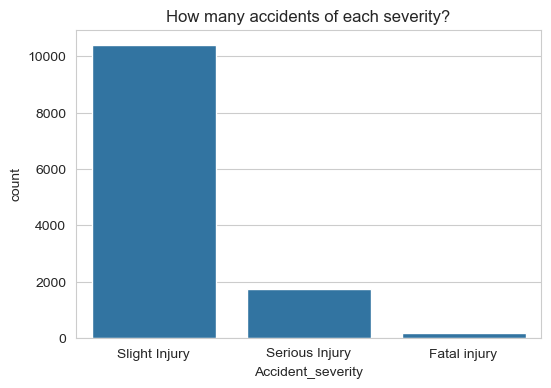

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
order = ["Slight Injury", "Serious Injury", "Fatal injury"]
sns.countplot(data=data, x=target, order=order, ax=ax)
ax.set_title("How many accidents of each severity?")
plt.show()

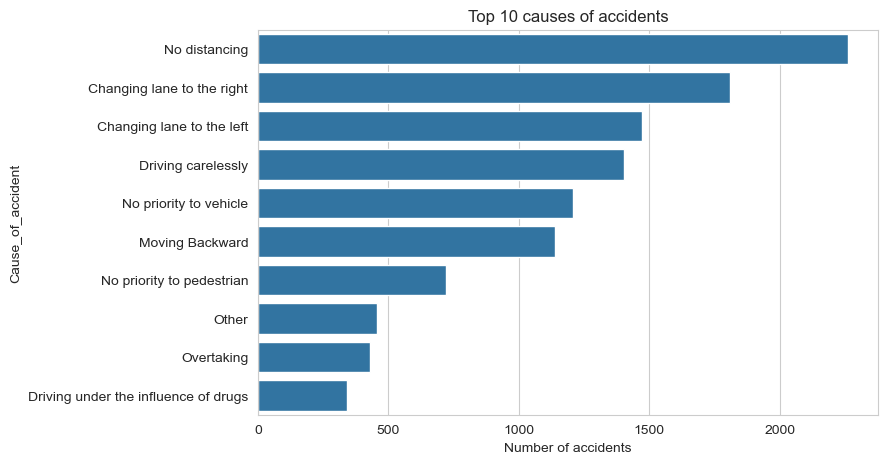

In [8]:
# Which causes are most common?
top_causes = data["Cause_of_accident"].value_counts().head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=top_causes.values, y=top_causes.index)
plt.title("Top 10 causes of accidents")
plt.xlabel("Number of accidents")
plt.show()

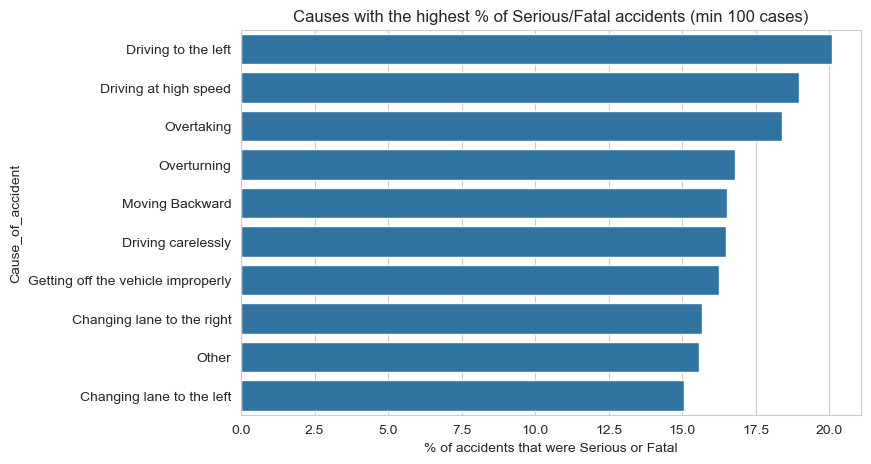

In [9]:
# Which causes lead to the MOST SEVERE accidents? (share of accidents that were Serious or Fatal)
data["Severe"] = data[target].isin(["Serious Injury", "Fatal injury"])
cause_stats = data.groupby("Cause_of_accident")["Severe"].agg(["mean", "count"])
cause_stats = cause_stats[cause_stats["count"] >= 100].sort_values("mean", ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=cause_stats["mean"] * 100, y=cause_stats.index)
plt.title("Causes with the highest % of Serious/Fatal accidents (min 100 cases)")
plt.xlabel("% of accidents that were Serious or Fatal")
plt.show()

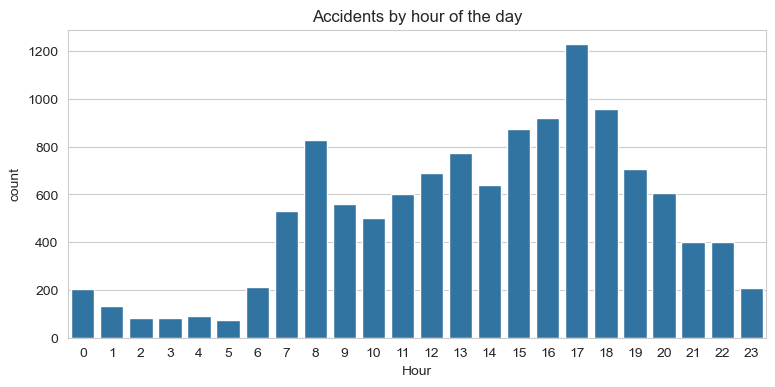

In [10]:
# Accidents by hour of the day
plt.figure(figsize=(9, 4))
sns.countplot(data=data, x="Hour")
plt.title("Accidents by hour of the day")
plt.show()

In [11]:
# Light conditions vs severity
pd.crosstab(data["Light_conditions"], data[target], normalize="index").round(3) * 100

Accident_severity,Fatal injury,Serious Injury,Slight Injury
Light_conditions,,,
Darkness - lights lit,2.0,14.2,83.8
Darkness - lights unlit,0.0,17.5,82.5
Darkness - no lighting,2.6,25.5,71.9
Daylight,1.0,13.9,85.1


In [12]:
data = data.drop(columns=["Severe"])   # helper column, not needed for the model

## Step 5: Prepare data for the model

Machine learning models only understand numbers, but most of our columns are text (like "Raining"). We use **One-Hot Encoding**: each category becomes its own 0/1 column.

Example: `Weather = Raining` becomes `Weather_Raining = 1`, `Weather_Normal = 0`, `Weather_Fog = 0`...

**Train/test split:** we hide 20% of the data from the model while it learns, then test it on that hidden 20%. This shows how it would perform on new accidents.

`stratify=y` keeps the same percentage of Fatal accidents in both parts. Without it, the tiny Fatal class could end up unevenly split.

In [13]:
X = data[categorical_features + numeric_features]   # inputs
y = data[target]                                    # what we predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training rows:", X_train.shape[0], "| Testing rows:", X_test.shape[0])

Training rows: 9852 | Testing rows: 2464


In [14]:
# Preprocessing: one-hot encode text columns, scale number columns
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features),
])

## Step 6: Train the models

**Model 1: Logistic Regression (baseline).** A simple model that learns a weight for every feature and combines them to give probabilities for each class. Easy to explain, so it is our starting point.

**Model 2: Random Forest.** It builds many decision trees (like many "if-else" flowcharts), each trained on a random part of the data, then lets them *vote*. Many trees together are more accurate and stable than one tree. It also tells us which features matter most.

We train Random Forest twice to learn something important:
- **First try:** trees are allowed to grow deep. They can *memorise* the training data (**overfitting**) and mostly predict the common class.
- **Tuned version:** we limit the tree depth (`max_depth=8`) and require at least 5 rows per leaf (`min_samples_leaf=5`). This forces the trees to learn general patterns instead of memorising.

**`class_weight="balanced"`**: this is how we handle the imbalance. It tells the model that mistakes on rare classes (Fatal) cost more than mistakes on the common class (Slight).

A **Pipeline** joins preprocessing and the model into one object, so new data gets the same treatment automatically.

In [15]:
log_reg = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# First try: deep trees (tends to overfit)
rf_basic = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3,
        class_weight="balanced_subsample", random_state=42, n_jobs=-1,
    )),
])

# Tuned: shallower trees (generalises better)
rf = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,      # number of trees
        max_depth=8,           # maximum depth of each tree
        min_samples_leaf=5,    # minimum rows in each leaf
        class_weight="balanced", random_state=42, n_jobs=-1,
    )),
])

for model in (log_reg, rf_basic, rf):
    model.fit(X_train, y_train)
print("All models trained.")

All models trained.


## Step 7: Evaluate the models

Key terms (learn these for interviews):
- **Accuracy:** % of all predictions that were correct. Misleading here because of the imbalance.
- **Precision:** of the accidents the model *called* Fatal, how many really were Fatal?
- **Recall:** of the accidents that *really were* Fatal, how many did the model catch? For safety problems, recall on Serious/Fatal matters most, because missing a dangerous case is costly.
- **F1-score:** a single number balancing precision and recall.
- **Confusion matrix:** a table showing what the model predicted vs what really happened.

In [16]:
all_models = [("Logistic Regression", log_reg), ("Random Forest (first try)", rf_basic), ("Random Forest (tuned)", rf)]
for name, model in all_models:
    pred = model.predict(X_test)
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, pred, zero_division=0))

Logistic Regression
                precision    recall  f1-score   support

  Fatal injury       0.02      0.39      0.04        31
Serious Injury       0.18      0.39      0.25       349
 Slight Injury       0.88      0.47      0.61      2084

      accuracy                           0.46      2464
     macro avg       0.36      0.42      0.30      2464
  weighted avg       0.77      0.46      0.55      2464

Random Forest (first try)
                precision    recall  f1-score   support

  Fatal injury       0.00      0.00      0.00        31
Serious Injury       0.45      0.11      0.18       349
 Slight Injury       0.86      0.98      0.91      2084

      accuracy                           0.84      2464
     macro avg       0.44      0.36      0.36      2464
  weighted avg       0.79      0.84      0.80      2464

Random Forest (tuned)
                precision    recall  f1-score   support

  Fatal injury       0.08      0.23      0.11        31
Serious Injury       0.28    

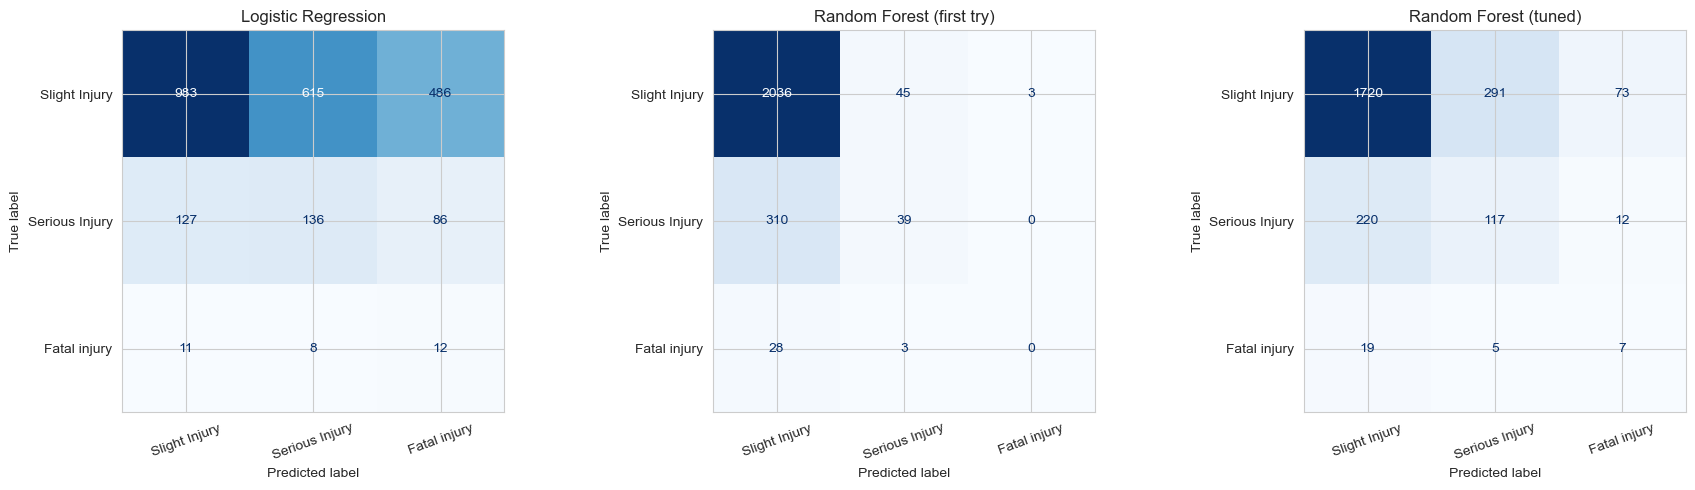

In [17]:
labels = ["Slight Injury", "Serious Injury", "Fatal injury"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, model) in zip(axes, all_models):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=20)
    ax.set_title(name)
plt.tight_layout()
plt.show()

**How to read the results (be honest in interviews):**
- **Random Forest (first try)** has 84% accuracy, but it almost always predicts "Slight Injury". It catches 0% of Fatal and only 10% of Serious cases. This is the accuracy trap caused by class imbalance.
- **Random Forest (tuned)** has lower accuracy (68%) but catches about 39% of Fatal and 38% of Serious cases. For a safety problem this is the more useful model, because missing a severe accident costs more than a false alarm.
- **Logistic Regression** catches a similar share of severe cases, but it is wrong more often on the common class (accuracy 46%).
- Precision for Fatal is very low (about 5%), so the model raises many false alarms. This is the precision/recall trade-off.
- The Fatal class has only 158 rows (31 in the test set), so its numbers are unstable. Predicting severity is hard here because the data lacks speed, seat-belt use and vehicle damage.

**Why we choose the tuned Random Forest:** the best balance across all three classes (highest macro-average recall and F1), and it gives feature importance.

## Step 8: Which factors matter most?

Random Forest can tell us how much each feature helped its decisions (**feature importance**). One-hot encoding splits one feature into many columns, so we add the columns back together per original feature.

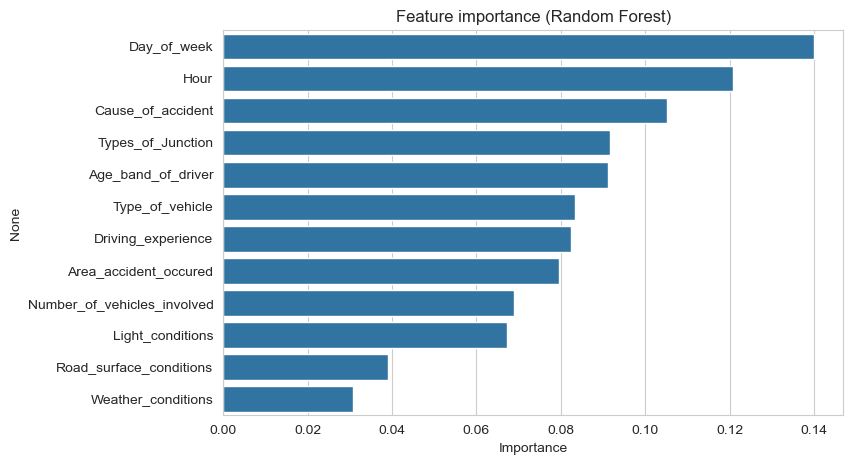

Day_of_week                    0.140
Hour                           0.121
Cause_of_accident              0.105
Types_of_Junction              0.092
Age_band_of_driver             0.091
Type_of_vehicle                0.083
Driving_experience             0.083
Area_accident_occured          0.080
Number_of_vehicles_involved    0.069
Light_conditions               0.067
Road_surface_conditions        0.039
Weather_conditions             0.031
dtype: float64

In [18]:
rf_model = rf.named_steps["model"]
feature_names = rf.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf_model.feature_importances_, index=feature_names)

# Add up one-hot columns that belong to the same original feature
grouped = {}
for feat in categorical_features + numeric_features:
    mask = [n.startswith(f"cat__{feat}_") or n == f"num__{feat}" for n in feature_names]
    grouped[feat] = importances[mask].sum()

grouped = pd.Series(grouped).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=grouped.values, y=grouped.index)
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.show()
grouped.round(3)

**Be careful when explaining this chart:** feature importance shows what the model *used* to make predictions, not what *causes* severe accidents. Features with many values (like Hour) tend to look more important in Random Forest. Say "these factors are most associated with severity in this dataset", not "these factors cause severe accidents".

## Step 9: Save the model for the Streamlit app

We save the trained pipeline to a file, plus the list of options for each dropdown in the app.

In [19]:
joblib.dump(rf, "model.pkl")

options = {col: sorted(data[col].unique().tolist()) for col in categorical_features}
options["Hour"] = list(range(24))
options["Number_of_vehicles_involved"] = sorted(data["Number_of_vehicles_involved"].unique().tolist())

with open("options.json", "w") as f:
    json.dump(options, f, indent=2)

print("Saved model.pkl and options.json")

Saved model.pkl and options.json


## Conclusion and limitations (write this in your README)

- Built a multi-class classifier for accident severity using Indian accident records.
- Random Forest was the main model and Logistic Regression the baseline. Limiting tree depth fixed the overfitting of the first Random Forest.
- Handled class imbalance with class weights and judged models by per-class recall and F1, not accuracy alone.
- Removed outcome columns to avoid data leakage.

**Limitations:** the dataset is small (12,316 rows), the Fatal class is very rare, and important factors like vehicle speed and seat-belt use are not recorded. The model is a decision-support and awareness tool, not a replacement for safety experts.

**Future work:** try XGBoost, add SMOTE oversampling, tune hyperparameters, and train on larger Indian datasets.